# Decorrelation Scale Analysis: Bootstrapping / Spatial Subsampling

This notebook tests whether the decorrelation scale calculated for densely sampled bays (like Tokyo Bay) is an artifact of the high station density.
We will perform a spatial subsampling (rarefaction) test: randomly dropping stations to match a lower density, and recalculating the decorrelation scale to see if it increases.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy import stats
from pathlib import Path
from tqdm.notebook import tqdm
import warnings

warnings.filterwarnings('ignore')

# Add project root to sys.path
current_dir = Path(os.getcwd()).resolve()
project_root = current_dir.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Parameters & Functions
We define the fixed parameters for the decorrelation analysis. It's crucial to use **fixed distance bins** (e.g., 12 km) instead of dynamically calculating them, so that the curve fitting remains consistent across bootstraps.

In [2]:
TARGET_BAY = 'Tokyo Bay'
FILTER_COL = 'watermass_name'
NUM_BOOTSTRAPS = 30
# Let's test by dropping down to 10 stations
TARGET_N_STATIONS = 10 

min_periods = 15
r_crit_alpha = 0.01
distance_cutoff_km = 100
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom'))

def gaussian_model_with_offset(x, A, dx):
    """Gaussian decay with offset, constrained: A + B = 1"""
    B = 1 - A
    return A * np.exp(-(x / dx)**2) + B

def calculate_r_crit(n, alpha=0.01):
    """Calculate critical correlation value for significance test."""
    if n < 3:
        return 1.0
    df = n - 2
    t_crit = stats.t.ppf(1 - alpha/2, df)
    r_crit = np.sqrt(t_crit**2 / (t_crit**2 + df))
    return r_crit

def count_neighbors_within_distance(target_station, dist_matrix, max_distance_km=100):
    """Count number of stations within max_distance_km of target_station"""
    distances = dist_matrix.loc[target_station]
    neighbors = distances[(distances > 0) & (distances <= max_distance_km)]
    return len(neighbors)

## 2. Data Loading

In [3]:
print("Loading data...")
# Note: we use read_feather instead of load_and_process_data as per the current pipeline
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Load yearly DO data from seasonal subset
subset_path = Path(subset_dir)
yearly_do_df_all = pd.read_csv(subset_path / 'yearly_do_df.csv', index_col=0)
yearly_do_df_all.index = yearly_do_df_all.index.astype(str).str.zfill(8)

bay_gdf = merged_gdf[merged_gdf[FILTER_COL] == TARGET_BAY].copy()
valid_stations = bay_gdf['zettaicode'].unique()
yearly_do_df = yearly_do_df_all[yearly_do_df_all.index.isin(valid_stations)].copy()

station_coords = bay_gdf[['zettaicode', 'geometry']].drop_duplicates('zettaicode')
station_coords = station_coords[station_coords['zettaicode'].isin(yearly_do_df.index)]
station_coords = station_coords.set_index('zettaicode')

stns_utm = gpd.GeoDataFrame(station_coords, geometry='geometry', crs=bay_gdf.crs).to_crs(epsg=32653)
coords_all = np.array([(geom.x, geom.y) for geom in stns_utm['geometry']])
coords_df = pd.DataFrame(coords_all, index=stns_utm.index, columns=['x', 'y'])

print(f"Total stations in {TARGET_BAY}: {len(stns_utm)}")

Loading data...
Total stations in Tokyo Bay: 28


## 3. Core Decorrelation Analysis Function
We wrap the decorrelation analysis into a function so we can run it repeatedly.

In [4]:
def calculate_decorrelation_scales(sampled_stations, coords_df_sampled, do_df_sampled):
    # Distance Matrix
    coords_array = coords_df_sampled.values
    dist_matrix = cdist(coords_array, coords_array) / 1000.0
    dist_matrix_km = pd.DataFrame(dist_matrix, index=sampled_stations, columns=sampled_stations)
    
    results_list = []
    
    for target_station in sampled_stations:
        target_series = do_df_sampled.loc[target_station]
        correlations = do_df_sampled.corrwith(target_series, axis=1, drop=True)
        
        valid_stats = []
        for neighbor in sampled_stations:
            neigh_series = do_df_sampled.loc[neighbor]
            valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
            
            if valid_count >= min_periods:
                if neighbor == target_station:
                    corr_val, dist_val = 1.0, 0.0
                else:
                    corr_val = correlations[neighbor]
                    dist_val = dist_matrix_km.loc[target_station, neighbor]
                
                if not np.isnan(corr_val) and not np.isnan(dist_val) and dist_val <= distance_cutoff_km:
                    valid_stats.append({'dist': dist_val, 'corr': corr_val, 'n': valid_count})
                    
        df_fit = pd.DataFrame(valid_stats)
        if len(df_fit) < 5: continue
        
        x_data, y_data = df_fit['dist'].values, df_fit['corr'].values
        
        try:
            popt, pcov = curve_fit(
                gaussian_model_with_offset, x_data, y_data,
                p0=[1.0, 50.0], bounds=([0, 0.001], [2.0, np.inf])
            )
            A_fit, dx_fit_param = popt
            B_fit = 1 - A_fit
            
            n_neighbors_100km = count_neighbors_within_distance(target_station, dist_matrix_km, distance_cutoff_km)
            r_crit = calculate_r_crit(n_neighbors_100km, alpha=r_crit_alpha) if n_neighbors_100km >= 2 else calculate_r_crit(df_fit['n'].mean(), alpha=r_crit_alpha)
            
            inner_val = (r_crit - B_fit) / A_fit
            if (A_fit > 0 and inner_val > 0 and inner_val < 1):
                decorr_scale = dx_fit_param * np.sqrt(-np.log(inner_val))
            else:
                decorr_scale = 0.0
                
            if decorr_scale > 0:
                results_list.append(decorr_scale)
        except Exception:
            pass
            
    return results_list

## 4. Run the Baseline (All Stations)
First, let's calculate the median decorrelation scale using all available stations.

In [5]:
baseline_scales = calculate_decorrelation_scales(stns_utm.index, coords_df, yearly_do_df)
baseline_median = np.median(baseline_scales) if len(baseline_scales) > 0 else np.nan
print(f"Baseline Median Decorrelation Scale ({len(stns_utm)} stations): {baseline_median:.2f} km")

Baseline Median Decorrelation Scale (28 stations): 4.86 km


## 5. Run the Bootstrapping
Now we randomly sample `TARGET_N_STATIONS` and recalculate the median scale for `NUM_BOOTSTRAPS` iterations.

In [6]:
bootstrap_medians = []

for i in tqdm(range(NUM_BOOTSTRAPS), desc="Bootstrapping iterations"):
    # Randomly sample stations
    sampled_stations = np.random.choice(stns_utm.index, size=TARGET_N_STATIONS, replace=False)
    coords_sampled = coords_df.loc[sampled_stations]
    do_sampled = yearly_do_df.loc[sampled_stations]
    
    scales = calculate_decorrelation_scales(sampled_stations, coords_sampled, do_sampled)
    
    if len(scales) > 0:
        bootstrap_medians.append(np.median(scales))

Bootstrapping iterations:   0%|          | 0/30 [00:00<?, ?it/s]

## 6. Results Visualization
Let's plot the distribution of the bootstrapped median decorrelation scales compared to the baseline.

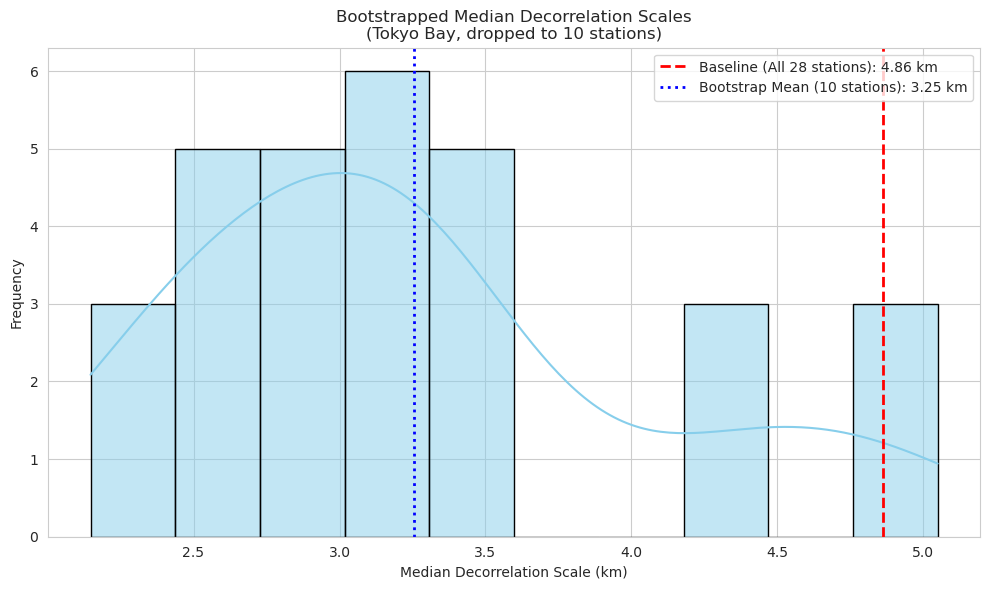

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(bootstrap_medians, bins=10, kde=True, color='skyblue', edgecolor='black')
plt.axvline(baseline_median, color='red', linestyle='dashed', linewidth=2, label=f'Baseline (All {len(stns_utm)} stations): {baseline_median:.2f} km')
plt.axvline(np.mean(bootstrap_medians), color='blue', linestyle='dotted', linewidth=2, label=f'Bootstrap Mean ({TARGET_N_STATIONS} stations): {np.mean(bootstrap_medians):.2f} km')

plt.title(f'Bootstrapped Median Decorrelation Scales\n({TARGET_BAY}, dropped to {TARGET_N_STATIONS} stations)')
plt.xlabel('Median Decorrelation Scale (km)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Conclusion
- **If the Bootstrap Mean is significantly higher than the Baseline:** The decorrelation scale is highly sensitive to station density. Your original results were likely constrained by the nearest-neighbor distance (a sampling artifact).
- **If the Bootstrap Mean is similar to the Baseline:** The decorrelation scale is robust to station density. The measured scale is likely a true representation of the physical dynamics in the bay.